# Principais bibliotecas de Machine Learning

Na aula de hoje, vamos conhecer as principais ferramentas de machine learning! As bibliotecas **Pandas**, **Numpy**, **Matplotlib** e **Scikit-Learn**.

Vamos lá!

Começando pelo pandas!

A biblioteca do pandas possui uma variedade de ferramentas para manipulação e análise de dados. Vamos conhecer algumas delas na aula de hoje!

In [1]:
# Instalando o Pandas

%pip install pandas

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\Tauap\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


# Importando os dados

In [2]:
import pandas as pd
from pathlib import Path

def localizar_arquivo(nome):
    candidatos = (
        Path(nome),
        Path("Base de Dados") / nome,
        Path("../Base de Dados") / nome,
        Path("02 - Machine Learning com Python/Aula 01/Base de Dados") / nome,
        Path("Fase 2/02 - Machine Learning com Python/Aula 01/Base de Dados") / nome,
    )
    caminho = next((c for c in candidatos if c.is_file()), None)
    if caminho is None:
        raise FileNotFoundError(f"{nome} nao encontrado. Pasta atual: {Path.cwd()}")
    return caminho

In [3]:
#Importando um Excel
from pathlib import Path

candidatos = (
    Path("Chess.xlsx"),
    Path("Base de Dados/Chess.xlsx"),
    Path("../Base de Dados/Chess.xlsx"),
    Path("02 - Machine Learning com Python/Aula 01/Base de Dados/Chess.xlsx"),
)
caminho_excel = next((caminho for caminho in candidatos if caminho.is_file()), None)
if caminho_excel is None:
    raise FileNotFoundError(f"Chess.xlsx não encontrado. Pasta atual: {Path.cwd()}")

df_excel = pd.read_excel(localizar_arquivo("Chess.xlsx"), sheet_name="Chess")

In [4]:
#Importando um csv
df_csv = pd.read_csv(localizar_arquivo("Tomato.csv"), sep=",")

# Conhecendo os dados

In [5]:
df_excel.head(3)

,rated,created_at,last_move_at,turns,victory_status,winner,increment_code,white_id,white_rating,black_id,black_rating,opening_eco,opening_name,opening_ply
0,False,1.504210e+17,1.504210e+17,13,outoftime,white,15+2,bourgris,1500,a-00,1191,D10,Slav Defense: Exchange Variation,5
1,True,1.504130e+17,1.504130e+17,16,resign,black,5+10,a-00,1322,skinnerua,1261,B00,Nimzowitsch Defense: Kennedy Variation,4
2,True,1.504130e+17,1.504130e+17,61,mate,white,5+10,ischia,1496,a-00,1500,C20,King's Pawn Game: Leonardis Variation,3


In [6]:
df_csv.head(3)

,Date,Unit,Minimum,Maximum,Average,Market
0,2013-06-16,Kg,26,32,29.0,Tomato
1,2013-06-17,Kg,20,25,22.5,Tomato
2,2013-06-18,Kg,22,26,24.0,Tomato


# Conhecendo a dimensão dos dados

In [7]:
df_excel.shape

(20058, 14)

In [8]:
df_csv.shape

(2741, 6)

# Analisando as informações dos dados

In [9]:
df_excel.info()

<class 'pandas.DataFrame'>
RangeIndex: 20058 entries, 0 to 20057
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   rated           20058 non-null  bool   
 1   created_at      20058 non-null  float64
 2   last_move_at    20058 non-null  float64
 3   turns           20058 non-null  int64  
 4   victory_status  20058 non-null  str    
 5   winner          20058 non-null  str    
 6   increment_code  20058 non-null  str    
 7   white_id        20058 non-null  object 
 8   white_rating    20058 non-null  int64  
 9   black_id        20058 non-null  object 
 10  black_rating    20058 non-null  int64  
 11  opening_eco     20058 non-null  str    
 12  opening_name    20058 non-null  str    
 13  opening_ply     20058 non-null  int64  
dtypes: bool(1), float64(2), int64(4), object(2), str(5)
memory usage: 2.0+ MB


In [10]:
df_csv.info()

<class 'pandas.DataFrame'>
RangeIndex: 2741 entries, 0 to 2740
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Date     2741 non-null   str    
 1   Unit     2741 non-null   str    
 2   Minimum  2741 non-null   int64  
 3   Maximum  2741 non-null   int64  
 4   Average  2741 non-null   float64
 5   Market   2741 non-null   str    
dtypes: float64(1), int64(2), str(3)
memory usage: 128.6 KB


# Analilsando estatísticas descritivas

In [11]:
df_excel.describe()

,created_at,last_move_at,turns,white_rating,black_rating,opening_ply
count,2.005800e+04,2.005800e+04,20058.000000,20058.000000,20058.000000,20058.000000
mean,6.321335e+16,6.313080e+16,60.465999,1596.631868,1588.831987,4.816981
std,7.292307e+16,7.290633e+16,33.570585,291.253376,291.036126,2.797152
min,1.376772e+12,1.376772e+12,1.000000,784.000000,789.000000,1.000000
25%,1.498313e+12,1.498315e+12,37.000000,1398.000000,1391.000000,3.000000
50%,1.504366e+12,1.504367e+12,55.000000,1567.000000,1562.000000,4.000000
75%,1.486680e+17,1.486680e+17,79.000000,1793.000000,1784.000000,6.000000
max,1.504470e+17,1.504470e+17,349.000000,2700.000000,2723.000000,28.000000


In [12]:
df_csv.describe().T

,count,mean,std,min,25%,50%,75%,max
Minimum,2741.0,35.089748,16.648425,8.0,22.0,30.0,45.0,115.0
Maximum,2741.0,41.281284,17.364135,12.0,30.0,38.0,50.0,120.0
Average,2741.0,38.185516,16.970949,10.0,25.0,35.0,47.5,117.5


# Conhecendo o conteúdo dos dados da coluna

In [13]:
set(df_excel['victory_status'])

{'draw', 'mate', 'outoftime', 'resign'}

# Adicionando colunas utilizando funções


In [14]:
# analisando os dados para criarmos uma nova coluna

df_csv.head(3)

,Date,Unit,Minimum,Maximum,Average,Market
0,2013-06-16,Kg,26,32,29.0,Tomato
1,2013-06-17,Kg,20,25,22.5,Tomato
2,2013-06-18,Kg,22,26,24.0,Tomato


In [15]:
df_csv.describe()

,Minimum,Maximum,Average
count,2741.000000,2741.000000,2741.000000
mean,35.089748,41.281284,38.185516
std,16.648425,17.364135,16.970949
min,8.000000,12.000000,10.000000
25%,22.000000,30.000000,25.000000
50%,30.000000,38.000000,35.000000
75%,45.000000,50.000000,47.500000
max,115.000000,120.000000,117.500000


In [16]:
# Função que implementa a condição
def categorizar_media(media):
    if media >= 40 and media <= 70:
        return 'tomate medio'
    elif media < 40:
        return 'tomate pequeno'
    else:
        return 'tomate grande'


In [17]:
# Aplicando a função na coluna 'Average' usando o método apply
df_csv['categoria_tomate'] = df_csv['Average'].apply(categorizar_media)


In [18]:
df_csv.groupby(['categoria_tomate']).describe()

Minimum                                                      \
                   count       mean       std   min   25%   50%   75%    max   
categoria_tomate                                                               
tomate grande      149.0  75.744966  7.324666  65.0  70.0  75.0  80.0  115.0   
tomate medio       954.0  47.818658  8.203065  30.0  40.0  45.0  55.0   65.0   
tomate pequeno    1638.0  23.978022  7.175572   8.0  18.0  25.0  30.0   38.0   

                 Maximum             ...              Average             \
                   count       mean  ...   75%    max   count       mean   
categoria_tomate                     ...                                   
tomate grande      149.0  82.583893  ...  85.0  120.0   149.0  79.164430   
tomate medio       954.0  55.009434  ...  60.0   75.0   954.0  51.414046   
tomate pequeno    1638.0  29.528694  ...  35.0   44.0  1638.0  26.753358   

                                                           
                       std   min   25%   50%   75%    max  
categoria_tomate                                           
tomate grande     7.367396  70.5  75.0  77.5  82.5  117.5  
tomate medio      8.272792  40.0  45.0  50.0  57.5   70.0  
tomate pequeno    7.191735  10.0  21.5  27.5  32.5   39.5  

[3 rows x 24 columns]

# Filtrando dados no pandas

In [19]:
filtro_tomate_pequeno = df_csv['Average'] < 40
df_csv.loc[filtro_tomate_pequeno]

,Date,Unit,Minimum,Maximum,Average,Market,categoria_tomate
0,2013-06-16,Kg,26,32,29.0,Tomato,tomate pequeno
1,2013-06-17,Kg,20,25,22.5,Tomato,tomate pequeno
2,2013-06-18,Kg,22,26,24.0,Tomato,tomate pequeno
3,2013-06-19,Kg,24,28,26.0,Tomato,tomate pequeno
4,2013-06-20,Kg,22,26,24.0,Tomato,tomate pequeno
...,...,...,...,...,...,...,...
2736,2021-05-09,Kg,10,15,12.5,Tomato,tomate pequeno
2737,2021-05-10,Kg,10,15,12.5,Tomato,tomate pequeno
2738,2021-05-11,Kg,10,15,12.5,Tomato,tomate pequeno
2739,2021-05-12,Kg,30,35,32.5,Tomato,tomate pequeno


## Conhecendo a biblioteca do numpy

Agora vamos conhecer mais de perto como funciona o numpy. O numpy é uma ferramenta poderosa com foco em manipular matrizes multidimensionais e processamento de matrizes.

Vamos conhecer alguns dos principais comandos:

In [20]:
%pip install numpy

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\Tauap\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [21]:
import numpy as np

# Criando arrays:

In [22]:
# Criando um array numpy a partir de uma lista
arr_list = np.array([1, 2, 3, 4, 5, 6, 7, 8])
print(arr_list)

[1 2 3 4 5 6 7 8]


In [23]:
# Criando um array numpy preenchido com zeros
arr_zeros = np.zeros((4, 6)) # matriz 4x6
print(arr_zeros)

[[0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]]


In [24]:
# Criando um array numpy preenchido com uns
arr_ones = np.ones((3, 4)) # matriz 3x4
print(arr_ones)

[[1. 1. 1. 1.]
 [1. 1. 1. 1.]
 [1. 1. 1. 1.]]


In [25]:
# Criando um array numpy com valores aleatórios entre 0 e 1
arr_random = np.random.rand(3, 4) # matriz 3x4
print(arr_random)

[[0.06827207 0.57620878 0.84205211 0.63895417]
 [0.44994314 0.13069151 0.58546116 0.25674126]
 [0.17563099 0.7852539  0.54024481 0.40776042]]


In [26]:
# Criando um array numpy com valores espaçados uniformemente
arr_range = np.arange(0, 10, 2) # array de 0 a 10 com passo 2
print(arr_range)

[0 2 4 6 8]


# Manipulando arrays:

In [27]:
# Obtendo a dimensão de um array
arr_dim = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9],  [10, 11, 12]])
print(arr_dim.shape) #4 linhas e 3 colunas

(4, 3)


In [28]:
arr_dim

array([[ 1,  2,  3],
       [ 4,  5,  6],
       [ 7,  8,  9],
       [10, 11, 12]])

In [29]:
# Mudando o formato de um array
arr_dim_3 = arr_dim.reshape((2, 6))
print(arr_dim_3) #redimensionando para 2 linhas e 6 colunas

[[ 1  2  3  4  5  6]
 [ 7  8  9 10 11 12]]


In [30]:
# Concatenando dois arrays ao longo de um eixo
arr1 = np.array([[1, 2], [3, 4]])
arr2 = np.array([[5, 6], [7, 8]])
arr3 = np.array([[9, 10], [11, 12]])
arr4 = np.concatenate((arr1, arr2, arr3), axis=1)
print(arr4)

[[ 1  2  5  6  9 10]
 [ 3  4  7  8 11 12]]


In [31]:
# Dividindo um array em vários sub-arrays
# Vamos utilizar o arr_dim

arr_dim

array([[ 1,  2,  3],
       [ 4,  5,  6],
       [ 7,  8,  9],
       [10, 11, 12]])

In [32]:
arr_split = np.split(arr_dim, 2)
print(arr_split)

[array([[1, 2, 3],
       [4, 5, 6]]), array([[ 7,  8,  9],
       [10, 11, 12]])]


In [33]:
# Transpondo um array
arr_dim_transpose = np.transpose(arr_dim)
print(arr_dim_transpose)

[[ 1  4  7 10]
 [ 2  5  8 11]
 [ 3  6  9 12]]


In [34]:
# Reverter o transpose
arr_transposed = arr_dim_transpose.T
print(arr_transposed)

[[ 1  2  3]
 [ 4  5  6]
 [ 7  8  9]
 [10 11 12]]


# Trabalhando com operações númericas

In [35]:
# Somando dois arrays
arr_a = np.array([1, 7, 27])
arr_b = np.array([5, 5, 3])
arr_add_ab = np.add(arr_a, arr_b)
print(arr_add_ab) # perceba que os arrays são somados

[ 6 12 30]


In [36]:
# Subtraindo dois arrays
arr_sub_ab = np.subtract(arr_a, arr_b)
print(arr_sub_ab)

[-4  2 24]


Use multiply para multiplicar e divide para dividir.

# Conhecendo o matplotlib

A ferramenta do matplotlib é uma ótima opção para a construção de gráficos de forma bem simples!

Vamos conhecer alguns exemplos:



In [37]:
%pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\Tauap\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [38]:
import matplotlib.pyplot as plt

In [39]:
# Vamos usar a base de tomates

tomates = df_csv
tomates.head(3)

,Date,Unit,Minimum,Maximum,Average,Market,categoria_tomate
0,2013-06-16,Kg,26,32,29.0,Tomato,tomate pequeno
1,2013-06-17,Kg,20,25,22.5,Tomato,tomate pequeno
2,2013-06-18,Kg,22,26,24.0,Tomato,tomate pequeno


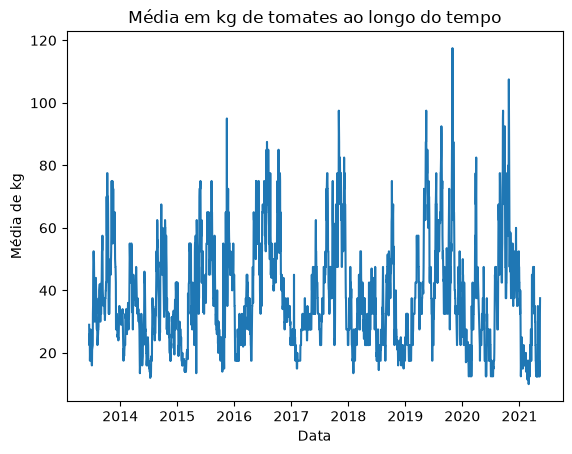

In [40]:
# Gráficos de linhas simples
tomates['Date'] = pd.to_datetime(tomates['Date'])

plt.plot(tomates['Date'], tomates['Average'])
plt.xlabel('Data')
plt.ylabel('Média de kg')
plt.title('Média em kg de tomates ao longo do tempo')
plt.show()

In [41]:
chess = df_excel
chess.head(3)

,rated,created_at,last_move_at,turns,victory_status,winner,increment_code,white_id,white_rating,black_id,black_rating,opening_eco,opening_name,opening_ply
0,False,1.504210e+17,1.504210e+17,13,outoftime,white,15+2,bourgris,1500,a-00,1191,D10,Slav Defense: Exchange Variation,5
1,True,1.504130e+17,1.504130e+17,16,resign,black,5+10,a-00,1322,skinnerua,1261,B00,Nimzowitsch Defense: Kennedy Variation,4
2,True,1.504130e+17,1.504130e+17,61,mate,white,5+10,ischia,1496,a-00,1500,C20,King's Pawn Game: Leonardis Variation,3


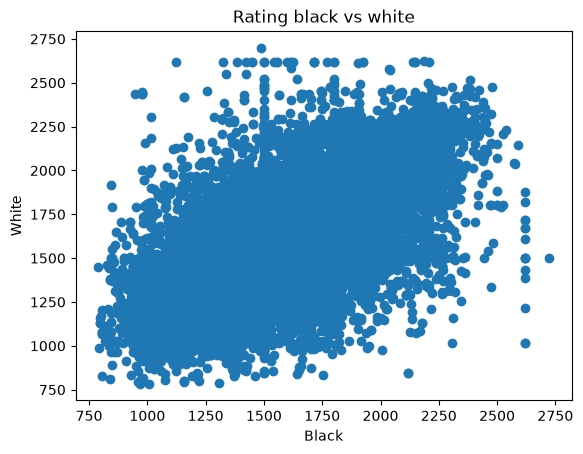

In [42]:
plt.scatter(chess['black_rating'], chess['white_rating'])
plt.xlabel('Black')
plt.ylabel('White')
plt.title('Rating black vs white')
plt.show()

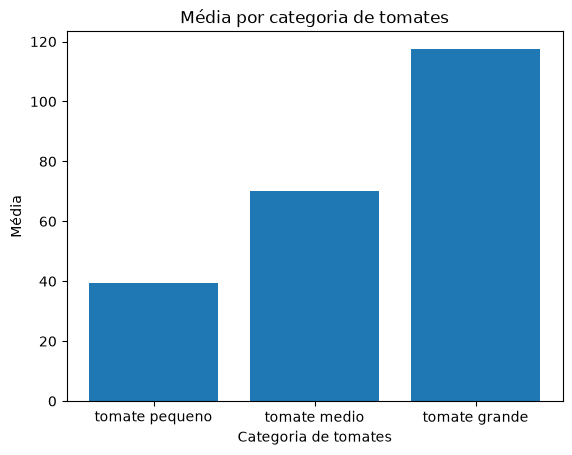

In [43]:
plt.bar(tomates['categoria_tomate'], tomates['Average'])
plt.xlabel('Categoria de tomates')
plt.ylabel('Média')
plt.title('Média por categoria de tomates')
plt.show()

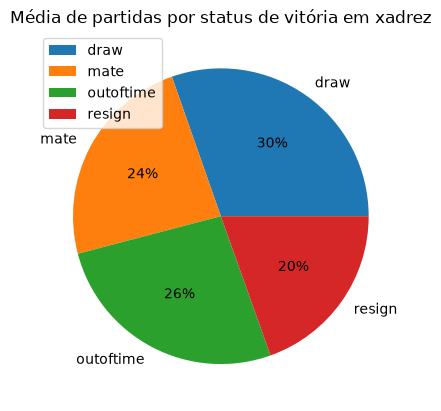

In [44]:
# Gráfico de pizza

chess.groupby(['victory_status']).mean(numeric_only=True).plot(kind='pie', y='turns', autopct='%1.0f%%')
plt.title('Média de partidas por status de vitória em xadrez')
plt.show()

# Conhecendo o Scikit-Learn

A biblioteca do scikit-Learn é uma poderosa biblioteca de ferramentas para trabalhar com os principais algoritmos de machine learning e deep learning, sem contar as inúmeras opções de ferramentas de transformações em dados.

In [45]:
%pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\Tauap\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [46]:
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

In [47]:
diabetes = pd.read_csv(localizar_arquivo("diabetes.csv"), sep=',')

In [48]:
diabetes.head(3)

,Number of times pregnant,Plasma glucose concentration a 2 hours in an oral glucose tolerance test,Diastolic blood pressure (mm Hg),Triceps skin fold thickness (mm),2-Hour serum insulin (mu U/ml),Body mass index (weight in kg/(height in m)^2),Diabetes pedigree function,Age (years),Class variable
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1


In [49]:
# Separando os dados
x= diabetes.drop(['Class variable'],axis=1)
y = diabetes['Class variable']

In [50]:
# Dividindo o conjunto de dados em treinamento e teste
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3)

In [51]:
# Cria um classificador k-vizinhos mais próximos com k=3
knn = KNeighborsClassifier(n_neighbors=3)

In [52]:
# Treina o classificador
knn.fit(x_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [53]:
# Testar o classificador
accuracy = knn.score(x_test, y_test)
print("Acurácia: {:.2f}%".format(round(accuracy,2) * 100))

Acurácia: 68.00%
